In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

from wavelets import WaveletTransformOperator2D


from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


from msolver import VanillaGKS

# For reference, to match papers exactly:
# SGKS corresponds to msolver, MM2GKS ?
# SGKS (restarted) corresponds to msolver, MM1GKS
# SGKS (recycled) corresponds to msolver, MM2GKS ?
# PSGKS corresponds to msolver, MM2GKS
# PSGKB corresponds to pgkbsolver, MM2GKB
# FGK corresponds to fsolver, MM2FGK
# FLSQR-I corresponds to f2019solver, MM4FGK2019, with option I 
# FLSQR-R corresponds to f2019solver, MM4FGK2019, with option R
# FLSQR-W corresponds to f2019solver, MM4FGK2019, with option W <- we added this option ourselves, close to the method below
# IRW-FLSQR corresponds to fIRWsolver, MM2FGKIRW, with option IRW


from msolver import MM2GKS, MM1GKS
from pgkbsolver import MM2GKB
from fsolver import MM2FGK
from f2019solver import MM4FGK2019
from fIRWsolver import MM2FGKIRW


# Also the IAS imports
from msolver import IASGKS
from fsolver import IASFGK
from pgkbsolver import IASGKB
from f2019solver import IASFGK2019
from fIRWsolver import IASFGKIRW

In [7]:
image = np.zeros_like(jlinops.cameraman())
img_shape = image.shape
ground_truth = image.flatten()


# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
coeffs = np.zeros(L.shape[0])
num_nonzero = 100
indices = np.random.choice(len(coeffs), size=num_nonzero, replace=False)
coeffs[indices] = 1
image = (L.T @ coeffs).reshape(img_shape)
ground_truth = image.flatten()


A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

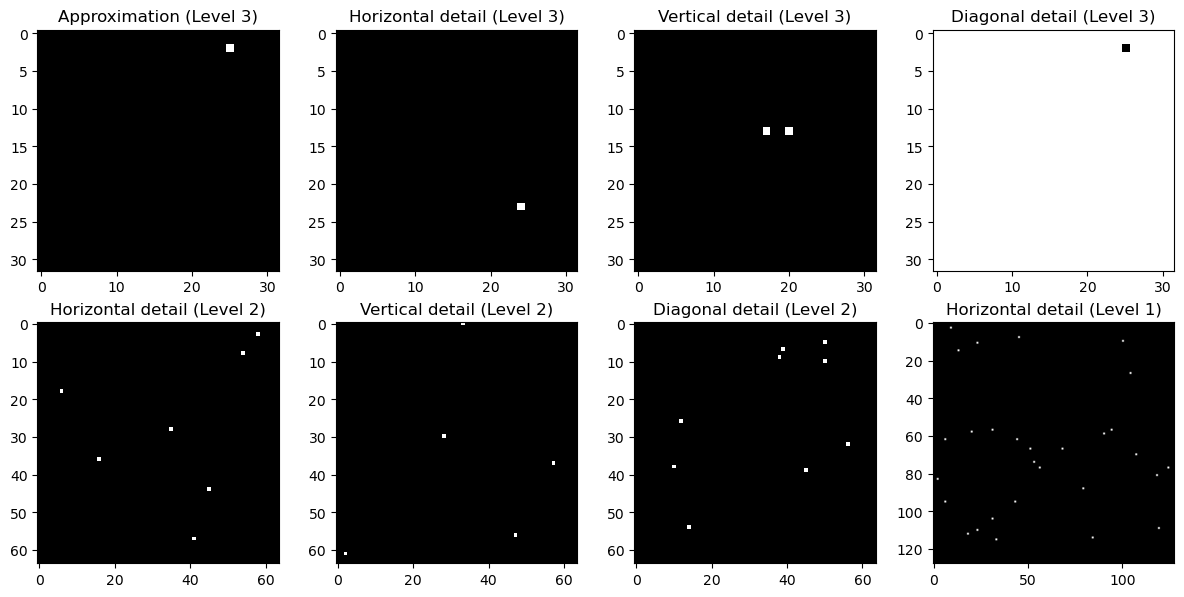

In [8]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


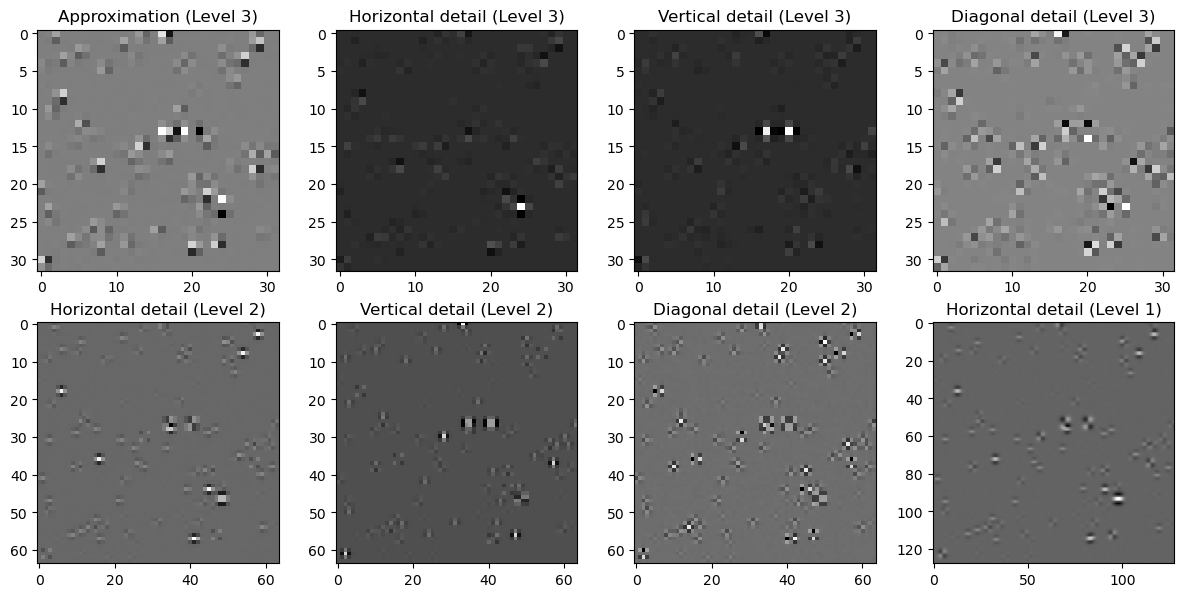

In [9]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


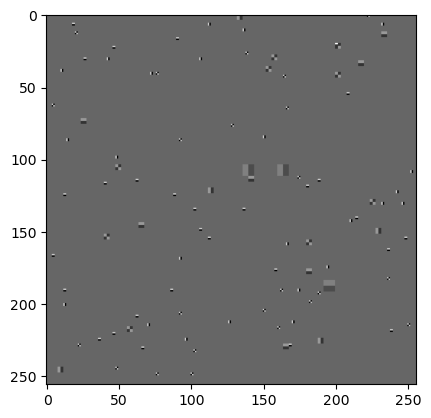

In [10]:
plt.imshow(image, cmap="gray")
plt.show()

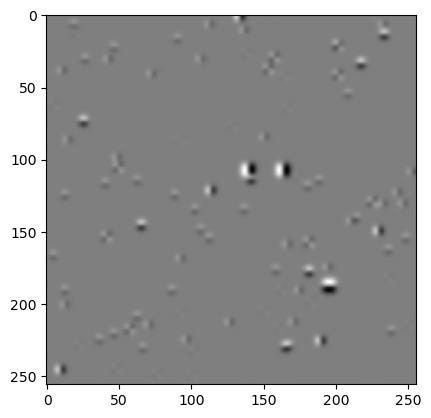

In [11]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Setup prior

In [12]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

In [13]:

xker = None

# Weight params

mm_weight_params = {
    "q": 1.0,
}

ias_weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}


# Setup solvers

In [14]:
# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# MM weights
mm1_gks_solver = MM1GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm2_gks_solver = MM2GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm2_fgk_solver = MM2FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm4_fgk2019_solver = MM4FGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Options I, R, W
mm2_fgkirw_solver = MM2FGKIRW(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Option IRW
mm2_psgkb_solver = MM2GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# IAS weights
ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk2019_solver = IASFGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
ias_fgkirw_solver = IASFGKIRW(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape) # Option IRW
ias_psgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

In [15]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-15

In [20]:
%%capture 

### MM weights (2019 version)

all_v_results = []

# Vanilla GKS
v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


all_mm_results = []

# S-GKS
mm_sgks_data = mm2_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )



# Recycled/restarted S-GKS
mm_sgks_resdata = mm1_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


mm_sgks_recdata = mm2_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
mm_psgks_data = mm2_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )

# PS-GKB
mm_psgkb_data = mm2_psgkb_solver.solve(n_iter=n_its, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"],
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "PS-GKB", mm_psgkb_data  ) )


# FGK
mm_fgk_data = mm2_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
mm_fgk2019I_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-I", mm_fgk2019I_data  ) )


mm_fgk2019R_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-R", mm_fgk2019R_data  ) )

mm_fgk2019W_data = mm4_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_mm_results.append( ( "MM", "FLSQR-W", mm_fgk2019W_data  ) )



mm_fgk2019IRW_data = mm2_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


all_mm_results.append( ( "MM", "IRW-FLSQR", mm_fgk2019IRW_data  ) )









In [21]:
%%capture 

### IAS weights


all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )



# Recycled/restarted S-GKS
ias_sgks_resdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=60)


ias_sgks_recdata = ias_gks_solver.solve(n_iter=800, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=30, max_dim=60, xker=xker, restart_dim=None)


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


ias_psgkb_data = ias_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "PS-GKB", ias_psgkb_data  ) )


# FGK
ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )

all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



# FGK2019 (there are four versions to do here.)
ias_fgk2019I_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-I", ias_fgk2019I_data  ) )


ias_fgk2019R_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-R", ias_fgk2019R_data  ) )

ias_fgk2019W_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=1e-13,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )

all_ias_results.append( ( "IAS", "FLSQR-W", mm_fgk2019W_data  ) )



ias_fgk2019IRW_data = ias_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


all_ias_results.append( ( "IAS", "IRW-FLSQR", ias_fgk2019IRW_data  ) )





# Save and make tables

In [36]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "HaarPSI":[], "Gini index": [], "A/A^T matvecs": [], "Lpinv/Lpinv^T matvecs": []})

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        # print(method_label)
        # print(method_data["rre_history"][-1])
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ]})
        ias_df = pd.concat([ias_df, new_df], axis=0)



In [37]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df.rename(columns={'lambdah': '$\lambda$'})
all_df.to_csv("2d_wavelet_cameraman_performance_results.csv")
all_df

,Weights,Method,$\lambda$,RRE,SSIM,HaarPSI,Gini index,Hoyer index
0,V,GKS,41.617725,0.117966,0.642471,0.999796,0.875512,0.832589
0,MM,S-GKS,24.560679,0.140969,0.702772,0.999578,0.962937,0.868132
0,MM,PS-GKS,23.751395,0.141988,0.712799,0.999597,0.977432,0.873488
0,MM,PS-GKB,23.903978,0.145932,0.707902,0.999549,0.977316,0.873597
0,MM,FGK,14.859771,0.129972,0.715695,0.999705,0.941038,0.859475
0,MM,FLSQR-I,2.428233,0.133110,0.719903,0.999651,0.974083,0.869246
0,MM,FLSQR-R,40.027058,0.124529,0.672396,0.999790,0.950733,0.856160
0,MM,FLSQR-W,18.814463,0.132369,0.722781,0.999654,0.973509,0.869181
0,MM,IRW-FLSQR,14.859771,0.129972,0.715695,0.999705,0.941038,0.859475
0,IAS,S-GKS,286.294912,0.162992,0.694400,0.999305,0.956966,0.868635


In [38]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [39]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", "HaarPSI": "${:.4e}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$"
                                                    }) )

\begin{tabular}{llrrrrrr}
\toprule
Weights & Method & $\lambda$ & RRE & SSIM & HaarPSI & Gini index & Hoyer index \\
\midrule
V & GKS & $4\cdot10^{1}$ & $0.118$ & $0.642$ & $9.9980e-01$ & $0.876$ & $0.833$ \\
MM & S-GKS & $2\cdot10^{1}$ & $0.141$ & $0.703$ & $9.9958e-01$ & $0.963$ & $0.868$ \\
MM & PS-GKS & $2\cdot10^{1}$ & $0.142$ & $0.713$ & $9.9960e-01$ & $0.977$ & $0.873$ \\
MM & PS-GKB & $2\cdot10^{1}$ & $0.146$ & $0.708$ & $9.9955e-01$ & $0.977$ & $0.874$ \\
MM & FGK & $1\cdot10^{1}$ & $0.130$ & $0.716$ & $9.9971e-01$ & $0.941$ & $0.859$ \\
MM & FLSQR-I & $2\cdot10^{0}$ & $0.133$ & $0.720$ & $9.9965e-01$ & $0.974$ & $0.869$ \\
MM & FLSQR-R & $4\cdot10^{1}$ & $0.125$ & $0.672$ & $9.9979e-01$ & $0.951$ & $0.856$ \\
MM & FLSQR-W & $2\cdot10^{1}$ & $0.132$ & $0.723$ & $9.9965e-01$ & $0.974$ & $0.869$ \\
MM & IRW-FLSQR & $1\cdot10^{1}$ & $0.130$ & $0.716$ & $9.9971e-01$ & $0.941$ & $0.859$ \\
IAS & S-GKS & $3\cdot10^{2}$ & $0.163$ & $0.694$ & $9.9931e-01$ & $0.957$ & $0.869$ \\
IAS & 

# Reconstruction plots

In [33]:
from skimage.metrics import structural_similarity

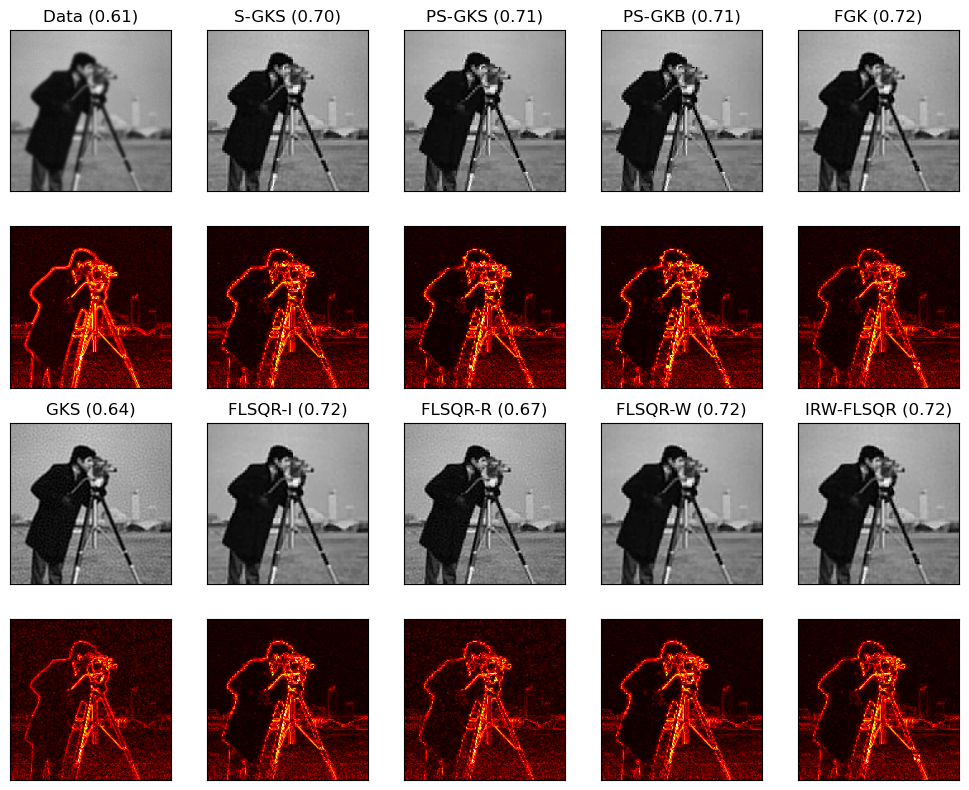

In [34]:
err_cmap = "hot"

vbound = 0.4
metric = "ssim_history"

fig, axs = plt.subplots(4,5,figsize=(10,8))


# Observed
perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title(f"Data ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# V-GKS
axs[2,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = v_gks_data[metric][-1]
axs[2,0].set_title(f"GKS ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])


# S-GKS
axs[0,1].imshow(mm_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( mm_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[0,2].imshow(mm_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_psgks_data[metric][-1]
axs[0,2].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( mm_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(mm_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_psgkb_data[metric][-1]
axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( mm_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mm_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk_data[metric][-1]
axs[0,4].set_title(f"FGK ({perf_metric:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mm_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])


# LSQR-I
axs[2,1].imshow(mm_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk2019I_data[metric][-1]
axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( mm_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# LSQR-R
axs[2,2].imshow(mm_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk2019R_data[metric][-1]
axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( mm_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])


# LSQR-W
axs[2,3].imshow(mm_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk2019W_data[metric][-1]
axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( mm_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# IRW-LSQR
axs[2,4].imshow(mm_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = mm_fgk2019IRW_data[metric][-1]
axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
axs[2,4].set_xticks([])
axs[2,4].set_yticks([])

axs[3,4].imshow(np.abs( mm_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,4].set_xticks([])
axs[3,4].set_yticks([])




fig.tight_layout()

fig.savefig("2d_wavelet_cameraman_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_wavelet_cameraman_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

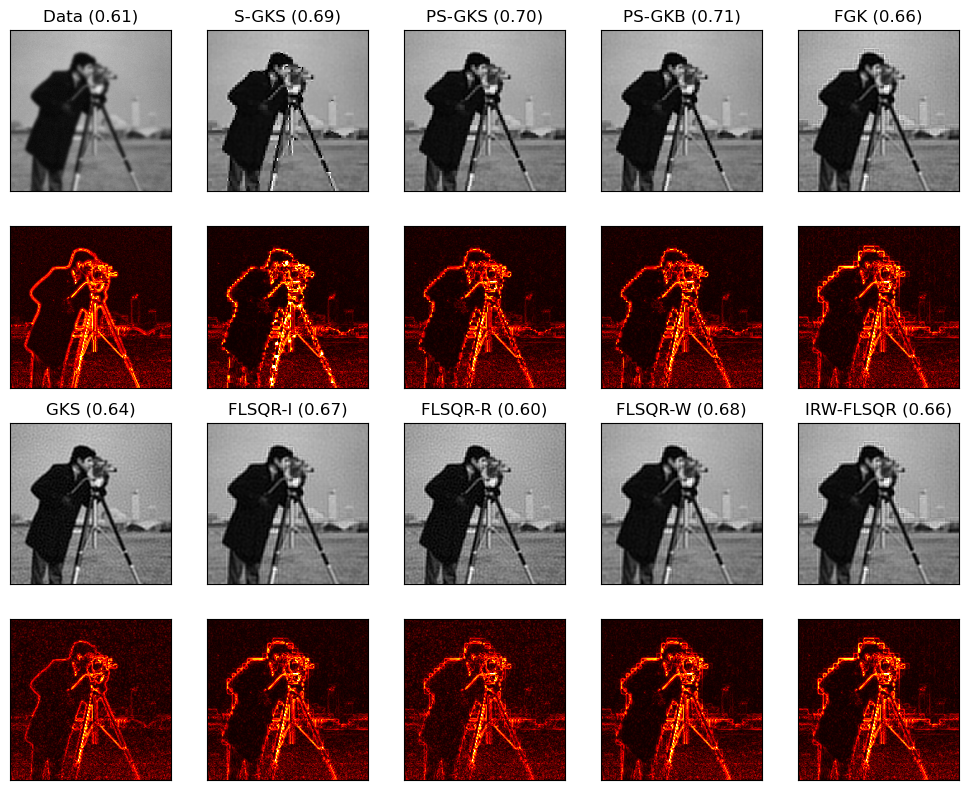

In [35]:
err_cmap = "hot"

vbound = 0.4
metric = "ssim_history"

fig, axs = plt.subplots(4,5,figsize=(10,8))


# Observed
perf_metric = structural_similarity( b.reshape(img_shape), ground_truth.reshape(img_shape), data_range=(np.amax(ground_truth) - np.amin(ground_truth) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False )
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title(f"Data ({perf_metric:.2f})")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# V-GKS
axs[2,0].imshow(v_gks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = v_gks_data[metric][-1]
axs[2,0].set_title(f"GKS ({perf_metric:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( v_gks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])


# S-GKS
axs[0,1].imshow(ias_sgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_sgks_data[metric][-1]
axs[0,1].set_title(f"S-GKS ({perf_metric:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( ias_sgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])



# PS-GKS
axs[0,2].imshow(ias_psgks_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_psgks_data[metric][-1]
axs[0,2].set_title(f"PS-GKS ({perf_metric:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( ias_psgks_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(ias_psgkb_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_psgkb_data[metric][-1]
axs[0,3].set_title(f"PS-GKB ({perf_metric:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( ias_psgkb_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(ias_fgk_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk_data[metric][-1]
axs[0,4].set_title(f"FGK ({perf_metric:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( ias_fgk_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])


# LSQR-I
axs[2,1].imshow(ias_fgk2019I_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk2019I_data[metric][-1]
axs[2,1].set_title(f"FLSQR-I ({perf_metric:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( ias_fgk2019I_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# LSQR-R
axs[2,2].imshow(ias_fgk2019R_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk2019R_data[metric][-1]
axs[2,2].set_title(f"FLSQR-R ({perf_metric:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( ias_fgk2019R_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])


# LSQR-W
axs[2,3].imshow(ias_fgk2019W_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk2019W_data[metric][-1]
axs[2,3].set_title(f"FLSQR-W ({perf_metric:.2f})")
axs[2,3].set_xticks([])
axs[2,3].set_yticks([])

axs[3,3].imshow(np.abs( ias_fgk2019W_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,3].set_xticks([])
axs[3,3].set_yticks([])




# IRW-LSQR
axs[2,4].imshow(ias_fgk2019IRW_data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
perf_metric = ias_fgk2019IRW_data[metric][-1]
axs[2,4].set_title(f"IRW-FLSQR ({perf_metric:.2f})")
axs[2,4].set_xticks([])
axs[2,4].set_yticks([])

axs[3,4].imshow(np.abs( ias_fgk2019IRW_data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,4].set_xticks([])
axs[3,4].set_yticks([])



fig.tight_layout()

fig.savefig("2d_wavelet_cameraman_reconstructions_ias.png", dpi=250, bbox_inches="tight")
fig.savefig("2d_wavelet_cameraman_reconstructions_ias.eps", format="eps", dpi=250, bbox_inches="tight")


plt.show()